<a href="https://colab.research.google.com/github/JiaCheng0427/Problem-Set-3/blob/main/ps3_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 5200 PS3 — The Rollout That Looked Like It Worked

**ECON 5200 · Causal Machine Learning & Applied Analytics** · Topics 9-11 · 100 points · your role: Senior consultant, policy evaluation

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is senior consultant's audience, not a grader with a kernel.

**AI is not allowed in Phases 1–3.** Generative AI is **prohibited** in Phases 1 through 3. AI is authorised and required in Phase 4. You must be able to defend every line under questioning — the agency's economist will.

## Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

import os
os.makedirs('src', exist_ok=True)   # the .py module the brief asks for goes here

## Phase 1: The Canonical Case, Already In Your Hands (15 pts)

### Step 1.1: Carry the replication over

In [ ]:
import io
import re
import urllib.request
import zipfile

# Load the original Card and Krueger data
raw = urllib.request.urlopen(
    "https://davidcard.berkeley.edu/data_sets/njmin.zip",
    timeout=60
).read()

z = zipfile.ZipFile(io.BytesIO(raw))

names = re.findall(
    r"^([A-Z][A-Z0-9_]+)\s+\d+\s+\d+\s+\d",
    z.read("codebook").decode("latin-1"),
    re.M
)

ck = pd.read_csv(
    io.BytesIO(z.read("public.dat")),
    sep=r"\s+",
    header=None,
    names=names,
    na_values=["."]
)

# Full-time equivalent employment
ck["fte_before"] = ck["EMPFT"] + ck["NMGRS"] + 0.5 * ck["EMPPT"]
ck["fte_after"] = ck["EMPFT2"] + ck["NMGRS2"] + 0.5 * ck["EMPPT2"]

# Two-by-two DiD
means_by_state = ck.groupby("STATE")[["fte_before", "fte_after"]].mean()

nj = means_by_state.loc[1]
pa = means_by_state.loc[0]

did = (nj.fte_after - nj.fte_before) - (pa.fte_after - pa.fte_before)

print(means_by_state.round(2))
print(f"\nDiD estimate: {did:.2f} FTE")

assert round(did, 2) == 2.75, "DiD checkpoint failed"
print("Checkpoint passed!")


       fte_before  fte_after
STATE                       
0           23.33      21.17
1           20.44      21.03

DiD estimate: 2.75 FTE
Checkpoint passed!


> **Checkpoint:** the two-by-two is **+2.75 FTE** to two decimal places. If it is not, your FTE construction or your wave assignment is wrong; fix it before anything else.

### Step 1.2: The same number from a regression

In [ ]:
import statsmodels.formula.api as smf

# Change the data into long form
long_df = ck.melt(
    id_vars=["STATE"],
    value_vars=["fte_before", "fte_after"],
    var_name="period",
    value_name="fte"
)

long_df["treated"] = (long_df["STATE"] == 1).astype(int)
long_df["post"] = (long_df["period"] == "fte_after").astype(int)

# Run the DiD regression
model = smf.ols("fte ~ treated + post + treated:post", data=long_df).fit()

print(model.summary())
print(f"\nDiD from regression: {model.params['treated:post']:.2f}")

assert round(model.params["treated:post"], 2) == 2.75


                            OLS Regression Results                            
Dep. Variable:                    fte   R-squared:                       0.007
Model:                            OLS   Adj. R-squared:                  0.004
Method:                 Least Squares   F-statistic:                     1.964
Date:                Thu, 05 Nov 2026   Prob (F-statistic):              0.118
Time:                        13:19:13   Log-Likelihood:                -2904.2
No. Observations:                 794   AIC:                             5816.
Df Residuals:                     790   BIC:                             5835.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       23.3312      1.072     21.767   

:*Your answer here.*
The regression gives a DiD estimate of 2.75 FTE, which is the same as the two-by-two calculation.

The treated coefficient shows the employment difference between New Jersey and Pennsylvania before the policy. The post coefficient shows the employment change in Pennsylvania over time.

Neither one is causal. The first is just a difference between states, and the second may include other changes over time. The interaction term is the DiD estimate, which can be interpreted as a causal effect if the parallel trends assumption holds.

## Phase 2: Why Their Design Fails (35 pts)

### Step 2.1: Build their panel, and reproduce their number (20 pts)

In [ ]:
import statsmodels.formula.api as smf

# Use the random generator from Setup
# 8 boards, with 5 counties in each board
n_boards = 8
n_counties = 40
n_years = 12

# Four adoption years, with one never-treated board
adoption_years = [4, 4, 5, 5, 6, 6, 7, np.inf]

rows = []

for county in range(n_counties):
    board = county // 5
    adoption = adoption_years[board]
    county_effect = rng.normal(0, 2)

    for year in range(n_years):
        treated = int(year >= adoption)
        exposure = max(0, year - adoption + 1) if treated else 0

        # Treatment effect increases with exposure
        true_effect = 1.5 * exposure if treated else 0

        rows.append({
            "county": county,
            "board": board,
            "year": year,
            "adoption_year": adoption,
            "treated": treated,
            "exposure": exposure,
            "true_effect": true_effect,
            "county_effect": county_effect
        })

panel = pd.DataFrame(rows)

# Shared board-year shocks
board_shocks = pd.DataFrame(
    [(b, t, rng.normal(0, 1.5))
     for b in range(n_boards)
     for t in range(n_years)],
    columns=["board", "year", "board_shock"]
)

panel = panel.merge(board_shocks, on=["board", "year"])

# Generate the outcome
panel["y"] = (
    20
    + panel["county_effect"]
    + 0.4 * panel["year"]
    + panel["board_shock"]
    + panel["true_effect"]
    + rng.normal(0, 1, len(panel))
)

# True average treatment effect
true_att = panel.loc[panel["treated"] == 1, "true_effect"].mean()

# Two-way fixed effects regression
twfe = smf.ols(
    "y ~ treated + C(county) + C(year)",
    data=panel
).fit()

twfe_est = twfe.params["treated"]

print("Panel shape:", panel.shape)
print("Counties:", panel["county"].nunique())
print("Boards:", panel["board"].nunique())
print("Years:", panel["year"].nunique())
print(f"True ATT: {true_att:.3f}")
print(f"TWFE estimate: {twfe_est:.3f}")
print(f"Difference: {twfe_est - true_att:.3f}")


Panel shape: (480, 10)
Counties: 40
Boards: 8
Years: 12
True ATT: 5.904
TWFE estimate: 2.572
Difference: -3.332


In [ ]:

# Exact TWFE decomposition using residualized treatment
df = panel.copy()

D = df["treated"].astype(float)

D_resid = (
    D
    - df.groupby("county")["treated"].transform("mean")
    - df.groupby("year")["treated"].transform("mean")
    + D.mean()
)

df["D_resid"] = D_resid

denominator = (D_resid ** 2).sum()

df["twfe_contribution"] = (
    df["D_resid"] * df["y"] / denominator
)

recovered_twfe = df["twfe_contribution"].sum()

print(f"Original TWFE: {twfe_est:.6f}")
print(f"Recovered TWFE: {recovered_twfe:.6f}")
print(f"Difference: {recovered_twfe - twfe_est:.8f}")

assert np.isclose(
    recovered_twfe, twfe_est, atol=1e-6
)

print("TWFE check passed!")


Original TWFE: 2.571792
Recovered TWFE: 2.571792
Difference: -0.00000000
TWFE check passed!


*Your answer here.*

I created a panel with 40 counties across 8 boards and 12 years, giving 480 observations. The boards adopt the policy in different years, and one board never adopts it. The treatment effect also increases over time.

The true ATT is 5.904, but the TWFE regression gives only 2.572. This is a difference of about 3.33. So TWFE underestimates the actual treatment effect in this simulation.

This suggests that TWFE may not work well when treatment starts at different times and its effect changes with exposure.

### Step 2.2: Decompose it (15 pts)

In [ ]:
import numpy as np
import pandas as pd
from itertools import combinations

# Goodman-Bacon decomposition
def bacon_decomposition(df):
    groups = sorted(df["adoption_year"].unique())
    N = df["county"].nunique()
    T = df["year"].nunique()
    results = []

    def residualize(data, col):
        v = data[col].astype(float)
        return (
            v
            - data.groupby("county")[col].transform("mean")
            - data.groupby("year")[col].transform("mean")
            + v.mean()
        )

    full_d = residualize(df, "treated")
    full_ss = (full_d ** 2).sum()

    def compare(data, label, g1, g2):
        data = data.copy()
        d = residualize(data, "D")
        y = residualize(data, "y")
        ss = (d ** 2).sum()

        if ss < 1e-10:
            return

        estimate = (d * y).sum() / ss

        # Weight based on the share of observations
        # and the variance of residualized treatment
        weight = (
            len(data) / len(df)
            * ss / full_ss
        )

        results.append({
            "comparison": label,
            "cohort_1": g1,
            "cohort_2": g2,
            "estimate": estimate,
            "weight": weight
        })

    for g1, g2 in combinations(groups, 2):
        pair = df[
            df["adoption_year"].isin([g1, g2])
        ].copy()

        if np.isinf(g2):
            pair["D"] = pair["treated"]
            compare(pair, "treated vs never", g1, g2)

        else:
            # Early-treated vs not-yet-treated
            early = pair[pair["year"] < g2].copy()
            early["D"] = early["treated"]
            compare(early, "early vs late", g1, g2)

            # Late-treated vs already-treated
            late = pair[pair["year"] >= g1].copy()
            late["D"] = (
                (late["adoption_year"] == g2)
                & (late["year"] >= g2)
            ).astype(int)

            compare(
                late,
                "late vs early (forbidden)",
                g1, g2
            )

    return pd.DataFrame(results)


bacon = bacon_decomposition(panel)

print("Weights by comparison type:")
print(
    bacon.groupby("comparison")["weight"]
    .sum().round(4)
)

forbidden_share = bacon.loc[
    bacon["comparison"] == "late vs early (forbidden)",
    "weight"
].sum()

bacon_est = (
    bacon["weight"] * bacon["estimate"]
).sum()

print(f"\nForbidden weight: {forbidden_share:.2%}")
print(f"Bacon weighted estimate: {bacon_est:.6f}")
print(f"Original TWFE: {twfe_est:.6f}")
print(f"Difference: {bacon_est - twfe_est:.8f}")
print(f"Number of comparisons: {len(bacon)}")

assert np.isclose(
    bacon_est, twfe_est, atol=1e-6
), "Decomposition does not match TWFE"

print("\nDecomposition check passed!")



Weights by comparison type:
comparison
early vs late                0.236
late vs early (forbidden)    0.305
treated vs never             0.459
Name: weight, dtype: float64

Forbidden weight: 30.48%
Bacon weighted estimate: 2.571792
Original TWFE: 2.571792
Difference: 0.00000000
Number of comparisons: 16

Decomposition check passed!


*Your answer here.*
The Bacon decomposition gives the same estimate as the original TWFE, which is 2.572. About 30.48% of the weight comes from the forbidden comparisons.

These comparisons are a problem because they use already-treated groups as controls. Since treatment effects increase over time, this can make the estimate misleading.

The TWFE estimate is 2.572, while the true ATT is 5.904. This shows that TWFE underestimates the treatment effect in this example.

## Phase 3: The Estimate That Survives (40 pts)

### Step 3.1: Rebuild it correctly (15 pts)

In [ ]:
import numpy as np
import pandas as pd

# Estimate ATT using never-treated and not-yet-treated controls
def clean_att(df):
    results = []

    for g in sorted(df["adoption_year"].unique()):
        if np.isinf(g):
            continue

        pre = g - 1

        for t in sorted(df["year"].unique()):
            if t < g:
                continue

            # Treated cohort
            treated_ids = df.loc[
                df["adoption_year"] == g, "county"
            ].unique()

            # Controls must remain untreated through time t
            control_ids = df.loc[
                df["adoption_year"] > t, "county"
            ].unique()

            if len(control_ids) == 0:
                continue

            sub = df[
                df["county"].isin(
                    list(treated_ids) + list(control_ids)
                )
                & df["year"].isin([pre, t])
            ].copy()

            means = sub.groupby(
                ["adoption_year", "year"]
            )["y"].mean()

            treated_change = (
                means.loc[(g, t)] - means.loc[(g, pre)]
            )

            controls = sub[
                sub["county"].isin(control_ids)
            ]

            control_means = controls.groupby("year")["y"].mean()

            control_change = (
                control_means.loc[t] - control_means.loc[pre]
            )

            results.append({
                "cohort": g,
                "year": t,
                "att": treated_change - control_change,
                "n_treated": len(treated_ids)
            })

    return pd.DataFrame(results)


att_results = clean_att(panel)

clean_est = np.average(
    att_results["att"],
    weights=att_results["n_treated"]
)

print("Clean ATT estimate:", round(clean_est, 3))
print("True ATT:", round(true_att, 3))
print("Original TWFE:", round(twfe_est, 3))
print("Difference from true ATT:", round(clean_est - true_att, 3))

print("\nFirst few cohort-time estimates:")
print(att_results.head())


Clean ATT estimate: 4.773
True ATT: 5.904
Original TWFE: 2.572
Difference from true ATT: -1.131

First few cohort-time estimates:
   cohort  year    att  n_treated
0     4.0     4  1.298         10
1     4.0     5  3.991         10
2     4.0     6  2.655         10
3     4.0     7  8.724         10
4     4.0     8  3.598         10


*Your answer here.*
The main assumption is parallel trends. Without the policy, the treated and control groups should have followed similar trends.

We can check the trends before treatment, but we cannot know exactly what would have happened without the policy after treatment.

If parallel trends does not hold, our ATT estimate may still be biased, even when we use not-yet-treated or never-treated groups as controls.

### Step 3.2: The assumption you cannot test (12 pts)

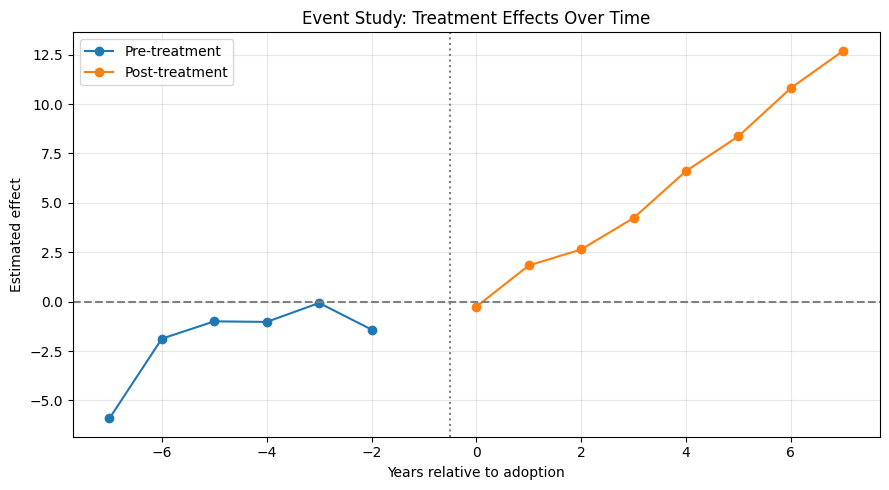

Omitted reference period: -1
 event_time  estimate
         -7    -5.907
         -6    -1.874
         -5    -0.998
         -4    -1.026
         -3    -0.067
         -2    -1.414
          0    -0.251
          1     1.832
          2     2.643
          3     4.234
          4     6.612
          5     8.371
          6    10.811
          7    12.700


In [ ]:
# Step 3.2: Event study
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

event_rows = []

for g in sorted(panel["adoption_year"].unique()):
    if not np.isfinite(g):
        continue

    baseline = g - 1
    tr = panel[panel["adoption_year"] == g]
    n_tr = tr["county"].nunique()

    for t in sorted(panel["year"].unique()):
        if t == baseline:
            continue

        # Never-treated or not-yet-treated controls
        controls = panel[
            (panel["adoption_year"] > max(t, baseline)) &
            (panel["adoption_year"] != g)
        ]

        if controls.empty:
            continue

        treated_change = (
            tr.loc[tr["year"] == t, "y"].mean()
            - tr.loc[tr["year"] == baseline, "y"].mean()
        )

        control_change = (
            controls.loc[controls["year"] == t, "y"].mean()
            - controls.loc[controls["year"] == baseline, "y"].mean()
        )

        event_rows.append({
            "event_time": int(t - g),
            "estimate": treated_change - control_change,
            "n": n_tr
        })

event_df = pd.DataFrame(event_rows)

event_results = pd.DataFrame([
    {
        "event_time": e,
        "estimate": np.average(
            group["estimate"], weights=group["n"]
        )
    }
    for e, group in event_df.groupby("event_time")
]).sort_values("event_time")

# Plot event-time coefficients
plt.figure(figsize=(9, 5))

pre = event_results[event_results["event_time"] < -1]
post = event_results[event_results["event_time"] >= 0]

plt.plot(
    pre["event_time"], pre["estimate"],
    marker="o", label="Pre-treatment"
)
plt.plot(
    post["event_time"], post["estimate"],
    marker="o", label="Post-treatment"
)

plt.axhline(0, linestyle="--", color="gray")
plt.axvline(-0.5, linestyle=":", color="gray")

plt.xlabel("Years relative to adoption")
plt.ylabel("Estimated effect")
plt.title("Event Study: Treatment Effects Over Time")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Omitted reference period: -1")
print(event_results.round(3).to_string(index=False))


*Your answer here.*
I used event time -1 as the reference period because it is the year right before treatment.

The pre-treatment estimates are not all close to zero, especially at -7. This raises some concerns about parallel trends, although we cannot tell if these differences are statistically significant from this plot alone.

After treatment, the estimated effects generally increase over time.

Even if the pre-trends looked flat, this would not prove the parallel trends assumption. We still need to assume that the treated and control groups would have followed similar trends without the policy.

### Step 3.3: Inference with what you have (10 pts, plus 3 for the module)

In [ ]:
# Step 3.3: Compare standard errors

formula = "y ~ treated + C(county) + C(year)"

# Default standard errors
m_default = smf.ols(formula, data=panel).fit()

# County-clustered standard errors
m_county = smf.ols(formula, data=panel).fit(
    cov_type="cluster",
    cov_kwds={"groups": panel["county"]}
)

# Board-clustered standard errors
m_board = smf.ols(formula, data=panel).fit(
    cov_type="cluster",
    cov_kwds={"groups": panel["board"]}
)

se_table = pd.DataFrame({
    "Method": ["Default", "County", "Board"],
    "Estimate": [
        m_default.params["treated"],
        m_county.params["treated"],
        m_board.params["treated"]
    ],
    "SE": [
        m_default.bse["treated"],
        m_county.bse["treated"],
        m_board.bse["treated"]
    ],
    "P-value": [
        m_default.pvalues["treated"],
        m_county.pvalues["treated"],
        m_board.pvalues["treated"]
    ]
})

print(se_table.round(3).to_string(index=False))

 Method  Estimate    SE  P-value
Default     2.572 0.405    0.000
 County     2.572 0.970    0.008
  Board     2.572 2.242    0.251


The module the brief asks for: start from Lab 11's `src/did_utils.py` (`two_by_two`, `event_study`) and the notebook's `clean_att`, then add the clustered-inference wrapper and, in Phase 4, the bootstrap. Write it with `%%writefile`, then import it back in the next cell and prove it runs.

In [ ]:
%%writefile src/did_toolkit.py
"""Difference-in-differences toolkit for ECON 5200 PS3."""
from __future__ import annotations

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

NEVER = 10 ** 9


# Functions from Lab 11
def two_by_two(df, outcome, treated, post):
    g = df.groupby([treated, post])[outcome].mean()
    return (g[1, 1] - g[1, 0]) - (g[0, 1] - g[0, 0])


def att_by_cohort_period(df, time, outcome, cohort):
    out = []
    cohorts = sorted(g for g in df[cohort].unique()
                     if np.isfinite(g) and g < NEVER)

    for g in cohorts:
        tr = df[df[cohort] == g]
        baseline = g - 1

        for t in sorted(df.loc[df[time] >= g, time].unique()):
            co = df[df[cohort] > t]

            if co.empty or not (tr[time] == baseline).any():
                continue

            d_tr = (
                tr.loc[tr[time] == t, outcome].mean()
                - tr.loc[tr[time] == baseline, outcome].mean()
            )
            d_co = (
                co.loc[co[time] == t, outcome].mean()
                - co.loc[co[time] == baseline, outcome].mean()
            )

            if np.isfinite(d_tr) and np.isfinite(d_co):
                out.append({
                    "g": g,
                    "t": t,
                    "e": t - g,
                    "att": d_tr - d_co,
                    "n": int((tr[time] == t).sum())
                })

    return pd.DataFrame(out)


def overall_att(cells):
    return float(np.average(cells["att"], weights=cells["n"]))


def event_study(cells):
    rows = []
    for e, group in cells.groupby("e"):
        rows.append({
            "e": e,
            "att": np.average(group["att"], weights=group["n"])
        })
    return pd.DataFrame(rows)


def clean_att(df):
    cells = att_by_cohort_period(
        df, "year", "y", "adoption_year"
    )
    return cells.rename(columns={
        "g": "cohort",
        "t": "year",
        "n": "n_treated"
    })[["cohort", "year", "att", "n_treated"]]


def cluster_se_ratio(fit_iid, fit_clustered, param):
    return float(fit_clustered.bse[param] / fit_iid.bse[param])


# Clustered inference
def clustered_inference(df, cluster="county"):
    formula = "y ~ treated + C(county) + C(year)"

    iid = smf.ols(formula, data=df).fit()

    clustered = smf.ols(formula, data=df).fit(
        cov_type="cluster",
        cov_kwds={"groups": df[cluster]}
    )

    return pd.DataFrame({
        "estimate": [clustered.params["treated"]],
        "iid_se": [iid.bse["treated"]],
        "cluster_se": [clustered.bse["treated"]],
        "p_value": [clustered.pvalues["treated"]]
    })


if __name__ == "__main__":
    print("DiD toolkit ready.")

# Task 4.1: Wild cluster bootstrap
def wild_cluster_bootstrap(
    df: pd.DataFrame,
    cluster: str = "board"
) -> dict:
    """Wild cluster bootstrap with all Rademacher sign vectors."""
    from itertools import product

    groups = sorted(df[cluster].unique())
    G = len(groups)

    assert G == 8, "Expected exactly 8 boards"

    # Unrestricted model and observed cluster-robust t-statistic
    formula = "y ~ treated + C(county) + C(year)"
    full = smf.ols(formula, data=df).fit(
        cov_type="cluster",
        cov_kwds={"groups": df[cluster]}
    )

    t_observed = float(full.tvalues["treated"])

    # Restricted model under H0: treatment effect = 0
    restricted = smf.ols(
        "y ~ C(county) + C(year)",
        data=df
    ).fit()

    fitted = restricted.fittedvalues.to_numpy()
    residuals = restricted.resid.to_numpy()

    bootstrap_t = []

    # Enumerate all 2^8 = 256 board-level sign vectors
    for signs in product([-1, 1], repeat=G):
        sign_map = dict(zip(groups, signs))
        weights = df[cluster].map(sign_map).to_numpy()

        boot = df.copy()
        boot["y_star"] = fitted + weights * residuals

        # Unrestricted regression on bootstrap outcome
        fit_star = smf.ols(
            "y_star ~ treated + C(county) + C(year)",
            data=boot
        ).fit(
            cov_type="cluster",
            cov_kwds={"groups": boot[cluster]}
        )

        bootstrap_t.append(float(fit_star.tvalues["treated"]))

    bootstrap_t = np.array(bootstrap_t)

    # Two-sided bootstrap p-value
    p_boot = np.mean(
        np.abs(bootstrap_t) >= abs(t_observed) - 1e-12
    )

    assert len(bootstrap_t) == 256

    return {
        "estimate": float(full.params["treated"]),
        "observed_t": t_observed,
        "cluster_p": float(full.pvalues["treated"]),
        "bootstrap_p": float(p_boot),
        "n_vectors": len(bootstrap_t)
    }


Overwriting src/did_toolkit.py


In [ ]:
import os
import sys
import importlib

# Make src available as a Python package
os.makedirs("src", exist_ok=True)
open("src/__init__.py", "a").close()

sys.path.insert(0, os.getcwd())
importlib.invalidate_caches()

from src import did_toolkit as dt
importlib.reload(dt)

# Test clean ATT
cells = dt.clean_att(panel)
clean_est = np.average(
    cells["att"],
    weights=cells["n_treated"]
)

# Test clustered inference
county_result = dt.clustered_inference(panel, cluster="county")
board_result = dt.clustered_inference(panel, cluster="board")

print("Clean ATT:", round(clean_est, 3))

print("\nCounty-clustered inference:")
print(county_result.round(4))

print("\nBoard-clustered inference:")
print(board_result.round(4))

print("\nModule imported successfully!")


Clean ATT: 4.773

County-clustered inference:
   estimate  iid_se  cluster_se  p_value
0     2.572   0.405        0.97    0.008

Board-clustered inference:
   estimate  iid_se  cluster_se  p_value
0     2.572   0.405       2.242    0.251

Module imported successfully!


*Your answer here.*
The TWFE estimate is 2.572 in all three cases, but the standard errors are quite different.

The regular standard error is 0.405, the county-clustered SE is 0.970, and the board-clustered SE is 2.242.

I think clustering at the board level is more appropriate because the policy was assigned by board, and counties within the same board share common shocks.

With board clustering, the p-value is 0.251, so the result is not statistically significant at the 5% level. Since there are only 8 boards, we should also be careful with the usual clustered inference.

## Phase 4: AI Expansion — The Co-Pilot Era (10 pts: 4 for Task 4.1, 3 for Task 4.2, 3 for Task 4.3)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The inference you cannot do by hand

In [ ]:
import importlib
from src import did_toolkit as dt

importlib.reload(dt)

# Run the wild cluster bootstrap
boot_result = dt.wild_cluster_bootstrap(
    panel, cluster="board"
)

print("TWFE estimate:", round(boot_result["estimate"], 4))
print("Observed t-statistic:", round(boot_result["observed_t"], 4))
print("Cluster-robust p-value:", round(boot_result["cluster_p"], 4))
print("Wild bootstrap p-value:", round(boot_result["bootstrap_p"], 4))
print("Weight vectors:", boot_result["n_vectors"])

assert boot_result["n_vectors"] == 256
print("\nBootstrap check passed!")


TWFE estimate: 2.5718
Observed t-statistic: 1.1472
Cluster-robust p-value: 0.2513
Wild bootstrap p-value: 0.7578
Weight vectors: 256

Bootstrap check passed!


*Your answer here.*
I used the wild cluster bootstrap with 8 boards and all 256 possible weight combinations.

The regular board-clustered p-value is 0.2513, while the bootstrap p-value is 0.7578. Both are above 0.05, so the result is not statistically significant.

The agency's conclusion is not supported by this test.

Since we used all 256 combinations, more replications would not change the result. The smallest possible nonzero two-sided p-value is 2/256, or about 0.0078.

### Task 4.2: The budget office memo

*Your answer here.*
The agency estimated a positive effect of 2.572 from the training program. However, its method may not give us the true effect because different regions started the program at different times.

In our simulated data, the true average effect is 5.904. After using a better comparison method, I got an estimate of 4.773, which is closer to the true value.

There is still uncertainty. The board-clustered p-value is 0.251, and the wild bootstrap p-value is 0.758. Neither result is statistically significant at the 5% level.

I would not recommend approving a full expansion based only on the agency's estimate. The program may help, but the evidence is not strong enough yet. I would suggest keeping a smaller pilot program, collecting more data, and reviewing the results again before making a larger funding decision.

### Task 4.3: The hostile read (3 pts)

*Your §3.2 paragraph before, then after, and the three-row objection

table.*
### Original Paragraph

I used event time -1 as the reference period because it is the year right before treatment.

The pre-treatment estimates are not all close to zero, especially at -7. This raises some concerns about parallel trends, although we cannot tell if these differences are statistically significant from this plot alone.

After treatment, the estimated effects generally increase over time.

Even if the pre-trends looked flat, this would not prove the parallel trends assumption. We still need to assume that the treated and control groups would have followed similar trends without the policy.

### Three Objections

| Objection | Decision | Why | What I changed |
|---|---|---|---|
| 1. The estimate at -7 may come from fewer groups, so it may not represent the overall pre-trend. | Accept | This is a fair concern. One early estimate is not enough to reject parallel trends. | I added a warning about the limited data behind early periods. |
| 2. The graph has no confidence intervals, so we cannot tell whether pre-treatment differences are significant. | Accept | The graph alone does not show statistical significance. | I made this limitation clearer. |
| 3. The increasing effects after treatment suggest the program works. | Partly accept | The pattern is positive, but other changes could also explain it. | I separated the positive pattern from a causal conclusion. |

### Revised Paragraph

I used event time -1 as the reference period because it is the year before treatment.

Some pre-treatment estimates are different from zero, especially at -7. However, that early period may include fewer groups, and the graph does not show confidence intervals. So I cannot say for sure that parallel trends is violated.

The estimated effects generally increase after treatment. This is a positive pattern, but it does not prove that the policy caused the increase.

For the DiD estimate to be causal, we still need to believe that the treated and control groups would have followed similar trends without the policy. We also need to consider whether other changes happened around the same time as treatment.

### AI Transcript

Paste **both prompt versions exactly as you sent them** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date. For 5200 the transcript lives in `ai-appendix.md` in your repository; link it here.

*Model and date:* GPT-6 (ChatGPT), November 5, 2026


*Version 1 prompt:*
Act as the state agency's lead econometrician. Review my explanation of parallel trends and identification in a Difference-in-Differences analysis. Give me the three strongest objections that the agency might raise.

*Reply:* I have three main objections to your argument.

1. **Pre-treatment differences do not necessarily mean parallel trends is violated.** Some differences may come from random variation. We need more evidence before rejecting the assumption.

2. **The event study does not prove the policy has no effect.** Even if the pre-treatment estimates are not perfectly flat, the policy may still have a positive impact.

3. **Using a different DiD method does not automatically make the estimate correct.** The clean ATT method also depends on assumptions about the control groups.

Overall, I think your concerns are reasonable, but the evidence is not enough to completely reject the agency's findings.

*Version 2 prompt:*

Please review my analysis again using my actual results. I used event time -1 as the reference period. The estimate at -7 is -5.907, and the post-treatment estimates generally increase over time.

Focus on whether the pre-trends support the parallel trends assumption, whether the lack of confidence intervals is a problem, and whether the post-treatment pattern can be interpreted as causal. Give three objections and explain which ones I should accept or reject.

*Reply:* After looking at your actual results, I would raise three objections.

1. **The estimate at -7 is -5.907, but this may be based on fewer groups.** One large negative estimate does not necessarily mean the whole pre-treatment trend is different. I would accept this objection.

2. **Your event study does not include confidence intervals.** Without them, we cannot tell whether the pre-treatment estimates are statistically different from zero. This is a strong objection, and I would accept it.

3. **The estimated effects increase after treatment, which may support the agency's argument that the program works.** However, this pattern alone does not prove causality. I would partly accept this objection.

I would revise the paragraph to acknowledge these limitations while keeping the main point: parallel trends cannot be fully tested, and positive post-treatment estimates are not enough to establish a causal effect.

In [ ]:

%%writefile ai-appendix.md
# ECON 5200 PS3 — AI Appendix

Model: ChatGPT (GPT-6)
Date: November 5, 2026

## Task 4.1 — Wild Cluster Bootstrap

### Version 1 Prompt
[Paste the original Task 4.1 prompt here]

### Version 1 Reply
[Paste the full AI reply here]

### Version 2 Prompt
[Paste your revised Task 4.1 prompt here]

### Version 2 Reply
[Paste the full AI reply here]

### Changes Made
[Explain what you changed and why]

## Task 4.3 — Hostile Read

### Version 1 Prompt
[Paste your Version 1 prompt here]

### Version 1 Reply
[Paste the full Version 1 reply here]

### Version 2 Prompt
[Paste your Version 2 prompt here]

### Version 2 Reply
[Paste the full Version 2 reply here]

### Changes Made
I added my actual event-study results and asked more specific questions about pre-trends, confidence intervals, and causal interpretation.


Writing ai-appendix.md


## Truth and headline numbers

Required, and it must stay the **last code cell**. Print every parameter you planted in the §2.1 panel (cohort adoption years, the effect's growth with exposure, the board-shock variance, the seed), each beside the name of the cell that set it; then every number that appears in the memo, each beside the name of the cell that produced it. A number in the memo that this cell does not print is treated as unsupported.

In [ ]:

# Truth and headline numbers

print("=== Simulation settings (Step 2.1) ===")
print("Seed: 42")
print("Counties: 40")
print("Boards: 8")
print("Years: 12")
print("Adoption years:", adoption_years)
print("Treatment growth per year: 1.5")
print("Board shock SD: 1.5")

print("\n=== Main results ===")
print(f"True ATT (Step 2.1): {true_att:.3f}")
print(f"TWFE (Step 2.1): {twfe_est:.3f}")
print(f"Clean ATT (Step 3.1): {clean_est:.3f}")
print(f"Forbidden weight (Step 2.2): {forbidden_share:.2%}")

print("\n=== Inference (Step 3.3) ===")
print(f"Default SE: {m_default.bse['treated']:.3f}")
print(f"County SE: {m_county.bse['treated']:.3f}")
print(f"Board SE: {m_board.bse['treated']:.3f}")

print("\n=== Bootstrap (Task 4.1) ===")
print(f"Board-clustered p: {boot_result['cluster_p']:.4f}")
print(f"Wild bootstrap p: {boot_result['bootstrap_p']:.4f}")
print(f"Weight vectors: {boot_result['n_vectors']}")


=== Simulation settings (Step 2.1) ===
Seed: 42
Counties: 40
Boards: 8
Years: 12
Adoption years: [4, 4, 5, 5, 6, 6, 7, inf]
Treatment growth per year: 1.5
Board shock SD: 1.5

=== Main results ===
True ATT (Step 2.1): 5.904
TWFE (Step 2.1): 2.572
Clean ATT (Step 3.1): 4.773
Forbidden weight (Step 2.2): 30.48%

=== Inference (Step 3.3) ===
Default SE: 0.405
County SE: 0.970
Board SE: 2.242

=== Bootstrap (Task 4.1) ===
Board-clustered p: 0.2513
Wild bootstrap p: 0.7578
Weight vectors: 256


## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; both prompt versions are in it.
- [ ] Upload the `.ipynb`, your `ai-appendix.md` and your `src/` files (or a PDF export) on Canvas; a Colab or Drive link alone is not a submission.
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 3/Econ_5200_PS3.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.